## Preparação da sessão e dos insumos

Execute a célula abaixo antes das atividades. Ela encontra o repositório na sessão local; no Colab, cria uma cópia em `/content/pos-graduacao-ia-ciencia-dados` apenas se essa pasta ainda não existir, sem alterar o diretório de trabalho. Um clone existente precisa ser atualizado por você quando necessário. Mudanças locais só ficam disponíveis nessa cópia do Colab após serem publicadas no remoto.

O corpus está em `dados/traducao/por.txt`, incluído no repositório. Consulte [as informações e atribuições do corpus](../../dados/traducao/README.md).

As saídas salvas e os nomes dos exemplos foram preservados como registros históricos. A preparação dos caminhos não valida a execução integral nem a compatibilidade das demais dependências.

In [ ]:
from pathlib import Path
import subprocess

SLUG = "processamento-linguagem-natural"
_session_dir = Path.cwd().resolve()
REPO_DIR = next(
    (p for p in (_session_dir, *_session_dir.parents)
     if (p / "disciplinas" / SLUG).is_dir()),
    None,
)
if REPO_DIR is None:
    if not Path("/content").is_dir():
        raise FileNotFoundError("Abra a sessão na raiz do repositório ou em uma de suas subpastas.")
    REPO_DIR = Path("/content/pos-graduacao-ia-ciencia-dados")
    if not REPO_DIR.exists():
        subprocess.run([
            "git", "clone", "--depth", "1",
            "https://github.com/wellingtonmnf/pos-graduacao-ia-ciencia-dados.git",
            str(REPO_DIR),
        ], check=True)

DISCIPLINA_DIR = REPO_DIR / "disciplinas" / SLUG
DATA_DIR = DISCIPLINA_DIR / "dados"
if not DISCIPLINA_DIR.is_dir() or not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Estrutura de dados ausente em {DISCIPLINA_DIR}. Atualize o clone para a revisão que contém dados/."
    )

TRADUCAO_PATH = DATA_DIR / "traducao" / "por.txt"
if not TRADUCAO_PATH.is_file():
    raise FileNotFoundError(f"Corpus ausente: {TRADUCAO_PATH}. Consulte {DATA_DIR / 'traducao' / 'README.md'}.")

In [ ]:
import os, sys, time, random
# O corpus é localizado pela célula de preparação, sem montagem do Drive.

Mounted at /content/drive


In [ ]:
# Corpus versionado em dados/traducao
data_dir = TRADUCAO_PATH.parent
file_path = TRADUCAO_PATH

print("Conteúdo do diretório:", os.listdir(data_dir))
print("Caminho do arquivo definido para:", file_path)

Conteúdo do diretório: ['_about.txt', 'por.txt', 'por-eng.zip']
Caminho do arquivo definido para: drive/MyDrive/Colab Notebooks/Pós-graduação | IA e Ciência de Dados/Processamento de Linguagem Natural/Unidade 05/datasets/por.txt


In [8]:
def load_data(path):
    with open(path, 'r', encoding='utf-8') as f:
        lines = f.read().split('\n')
    return lines

lines = load_data(file_path)
print(f'Carregadas {len(lines)} linhas')

Carregadas 168904 linhas


In [9]:
from keras.layers import *
from keras.models import *
from keras.utils import *
from keras.initializers import *
import tensorflow as tf
import h5py
import numpy as np

In [10]:
BATCH_SIZE = 64  # Batch size
NB_EPOCH = 100  # Número de épocas
latent_dim = 256  # Dimensão do espaço de encoding
num_samples = 10000  # Número de exemplos a serem treinados

In [11]:
%%time
# Modelagem matemática
input_texts = [] # Textos de entrada
target_texts = [] # Textos de saída
input_characters = set() # Caracteres de entrada
target_characters = set() # Caracteres de saída
i = 0
with open(file_path, 'r', encoding='utf-8') as f:
    lines = f.read().split('\n')
for line in lines[: min(num_samples, len(lines) - 1)]:
    input_text, target_text = line.split('\t',2)[:2]
    i = i + 1
    if i%500 == 0:
      print('Processing',i,input_text,target_text)
    # Usaremos "\t" como caractere inicial e "\n" como caractere final
    target_text = '\t' + target_text + '\n'
    input_texts.append(input_text)
    target_texts.append(target_text)
    for char in input_text:
        if char not in input_characters:
            input_characters.add(char)
    for char in target_text:
        if char not in target_characters:
            target_characters.add(char)

Processing 500 I'm tall. Eu sou alto.
Processing 1000 Look here. Olhe aqui.
Processing 1500 I think so. Acredito que sim.
Processing 2000 Who saw me? Quem me viu?
Processing 2500 I trust Tom. Eu confio em Tom.
Processing 3000 Tom cringed. Tom se encolheu.
Processing 3500 Did Tom call? Tom ligou?
Processing 4000 I'm a priest. Sou sacerdote.
Processing 4500 They are big. Eles são grandes.
Processing 5000 Will it rain? Será que vai chover?
Processing 5500 I do like Tom. Eu gosto muito do Tom.
Processing 6000 I'm busy here. Estou ocupado aqui.
Processing 6500 She got angry. Ela ficou brava.
Processing 7000 Tom was weary. O Tom estava cansado.
Processing 7500 Are you hungry? Você está com fome?
Processing 8000 I didn't sleep. Eu não dormi.
Processing 8500 I'm a diabetic. Sou diabética.
Processing 9000 Let's get them. Vamos pegá-las.
Processing 9500 They're stupid. Elas são estúpidas.
Processing 10000 We fight a lot. Nós brigamos muito.
CPU times: user 205 ms, sys: 69.6 ms, total: 275 ms
Wal

In [12]:
# Compreendendo o vocabulário
print('input_characters',input_characters)
print('target_characters',target_characters)

input_characters {'S', 'n', 'z', '.', 'Y', '3', '5', '2', 'j', '4', 'f', 'H', 't', 'm', ' ', 'i', 'y', 'q', '!', 'F', 'E', 'l', 'd', ':', 'u', '?', 'h', 'e', 'M', 'p', '7', 'O', '6', '8', 'b', 'W', 's', 'A', 'L', 'N', '0', 'Q', 'G', 'g', 'K', 'x', 'B', 'V', 'I', 'T', '-', 'J', 'k', ',', 'R', 'P', '#', '1', '$', 'w', '9', 'v', 'c', 'r', "'", 'U', 'o', 'C', 'a', 'D'}
target_characters {'S', '3', 'ô', 'i', 'F', 'l', 'Á', 'h', 'p', '8', 'N', 'L', '\n', 'x', 'V', 'ã', 'k', '1', 'ó', 'w', '\t', 'U', 'r', 'c', 'ê', 'o', 'C', '5', 't', 'É', 'E', 'y', '!', ':', 'u', 'e', 'b', 's', 'A', 'B', 'Â', 'P', 'a', 'n', '.', '2', 'j', '4', 'ç', 'H', ' ', 'à', 'ă', 'é', 'õ', '7', '-', 'O', '"', '0', 'K', 'I', 'T', 'J', '$', '9', 'v', 'ú', '\u200e', 'z', 'f', 'â', 'm', 'í', 'á', 'q', 'd', '?', 'M', 'W', 'Q', 'G', 'g', ',', 'R', 'D'}


In [13]:
%%time
input_characters = sorted(list(input_characters))
target_characters = sorted(list(target_characters))
num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max([len(txt) for txt in input_texts])
max_decoder_seq_length = max([len(txt) for txt in target_texts])
print('Number of samples:', len(input_texts))
print('Number of unique input tokens:', num_encoder_tokens)
print('Number of unique output tokens:', num_decoder_tokens)
print('Max sequence length for inputs:', max_encoder_seq_length)
print('Max sequence length for outputs:', max_decoder_seq_length)

Number of samples: 10000
Number of unique input tokens: 70
Number of unique output tokens: 86
Max sequence length for inputs: 15
Max sequence length for outputs: 45
CPU times: user 2.3 ms, sys: 0 ns, total: 2.3 ms
Wall time: 2.29 ms


In [14]:
%%time
# Criando o dataset codificado
input_token_index = dict([(char, i) for i, char in enumerate(input_characters)])
target_token_index = dict([(char, i) for i, char in enumerate(target_characters)])
# Criando a entrada do encoder, do decoder e da saída esperada
encoder_input_data = np.zeros((len(input_texts), max_encoder_seq_length, num_encoder_tokens),dtype='float32')
decoder_input_data = np.zeros((len(input_texts), max_decoder_seq_length, num_decoder_tokens),dtype='float32')
decoder_target_data = np.zeros((len(input_texts), max_decoder_seq_length, num_decoder_tokens),dtype='float32')
for i, (input_text, target_text) in enumerate(zip(input_texts, target_texts)):
    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.
    for t, char in enumerate(target_text):
        # decoder_target_data está na frente do decoder_input_data por um timestep
        decoder_input_data[i, t, target_token_index[char]] = 1.
        if t > 0:
            # decoder_target_data estará na frente por um timestep e não vai incluir o caractere de início '/t'
            decoder_target_data[i, t - 1, target_token_index[char]] = 1.
print('Spape of encoder_input_data',encoder_input_data.shape)
print('Spape of decoder_input_data',decoder_input_data.shape)
print('Spape of decoder_target_data',decoder_target_data.shape)

Spape of encoder_input_data (10000, 15, 70)
Spape of decoder_input_data (10000, 45, 86)
Spape of decoder_target_data (10000, 45, 86)
CPU times: user 178 ms, sys: 135 ms, total: 313 ms
Wall time: 315 ms


In [15]:
# Criando o modelo Seq2Seq
# Criando o encoder
encoder_inputs = Input(shape=(None, num_encoder_tokens))
encoder = LSTM(latent_dim, return_state=True)
encoder_outputs, state_h, state_c = encoder(encoder_inputs)
# Mantendo apenas os estados
encoder_states = [state_h, state_c]
# Criando o decoder
decoder_inputs = Input(shape=(None, num_decoder_tokens))
# O decoder vai retornar à sequência completa e ao estado interno, o qual
# não será utilizado no treinamento, mas na inferência apenas.
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = Dense(num_decoder_tokens, activation='softmax')
decoder_outputs = decoder_dense(decoder_outputs)
# O modelo final irá transformar o encoder_input_data & decoder_input_data em decoder_target_data
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, None, 86)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 256),     │    334,848 │ input_layer[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, None,     │    351,232 │ input_layer_1[0]… │
│                     │ 256), (None,      │            │ lstm[0][1],       │
│                     │ 256), (None,      │            │ lstm[0][2]        │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 86)  │     22,102 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 708,182 (2.70 MB)

 Trainable params: 708,182 (2.70 MB)

 Non-trainable params: 0 (0.00 B)

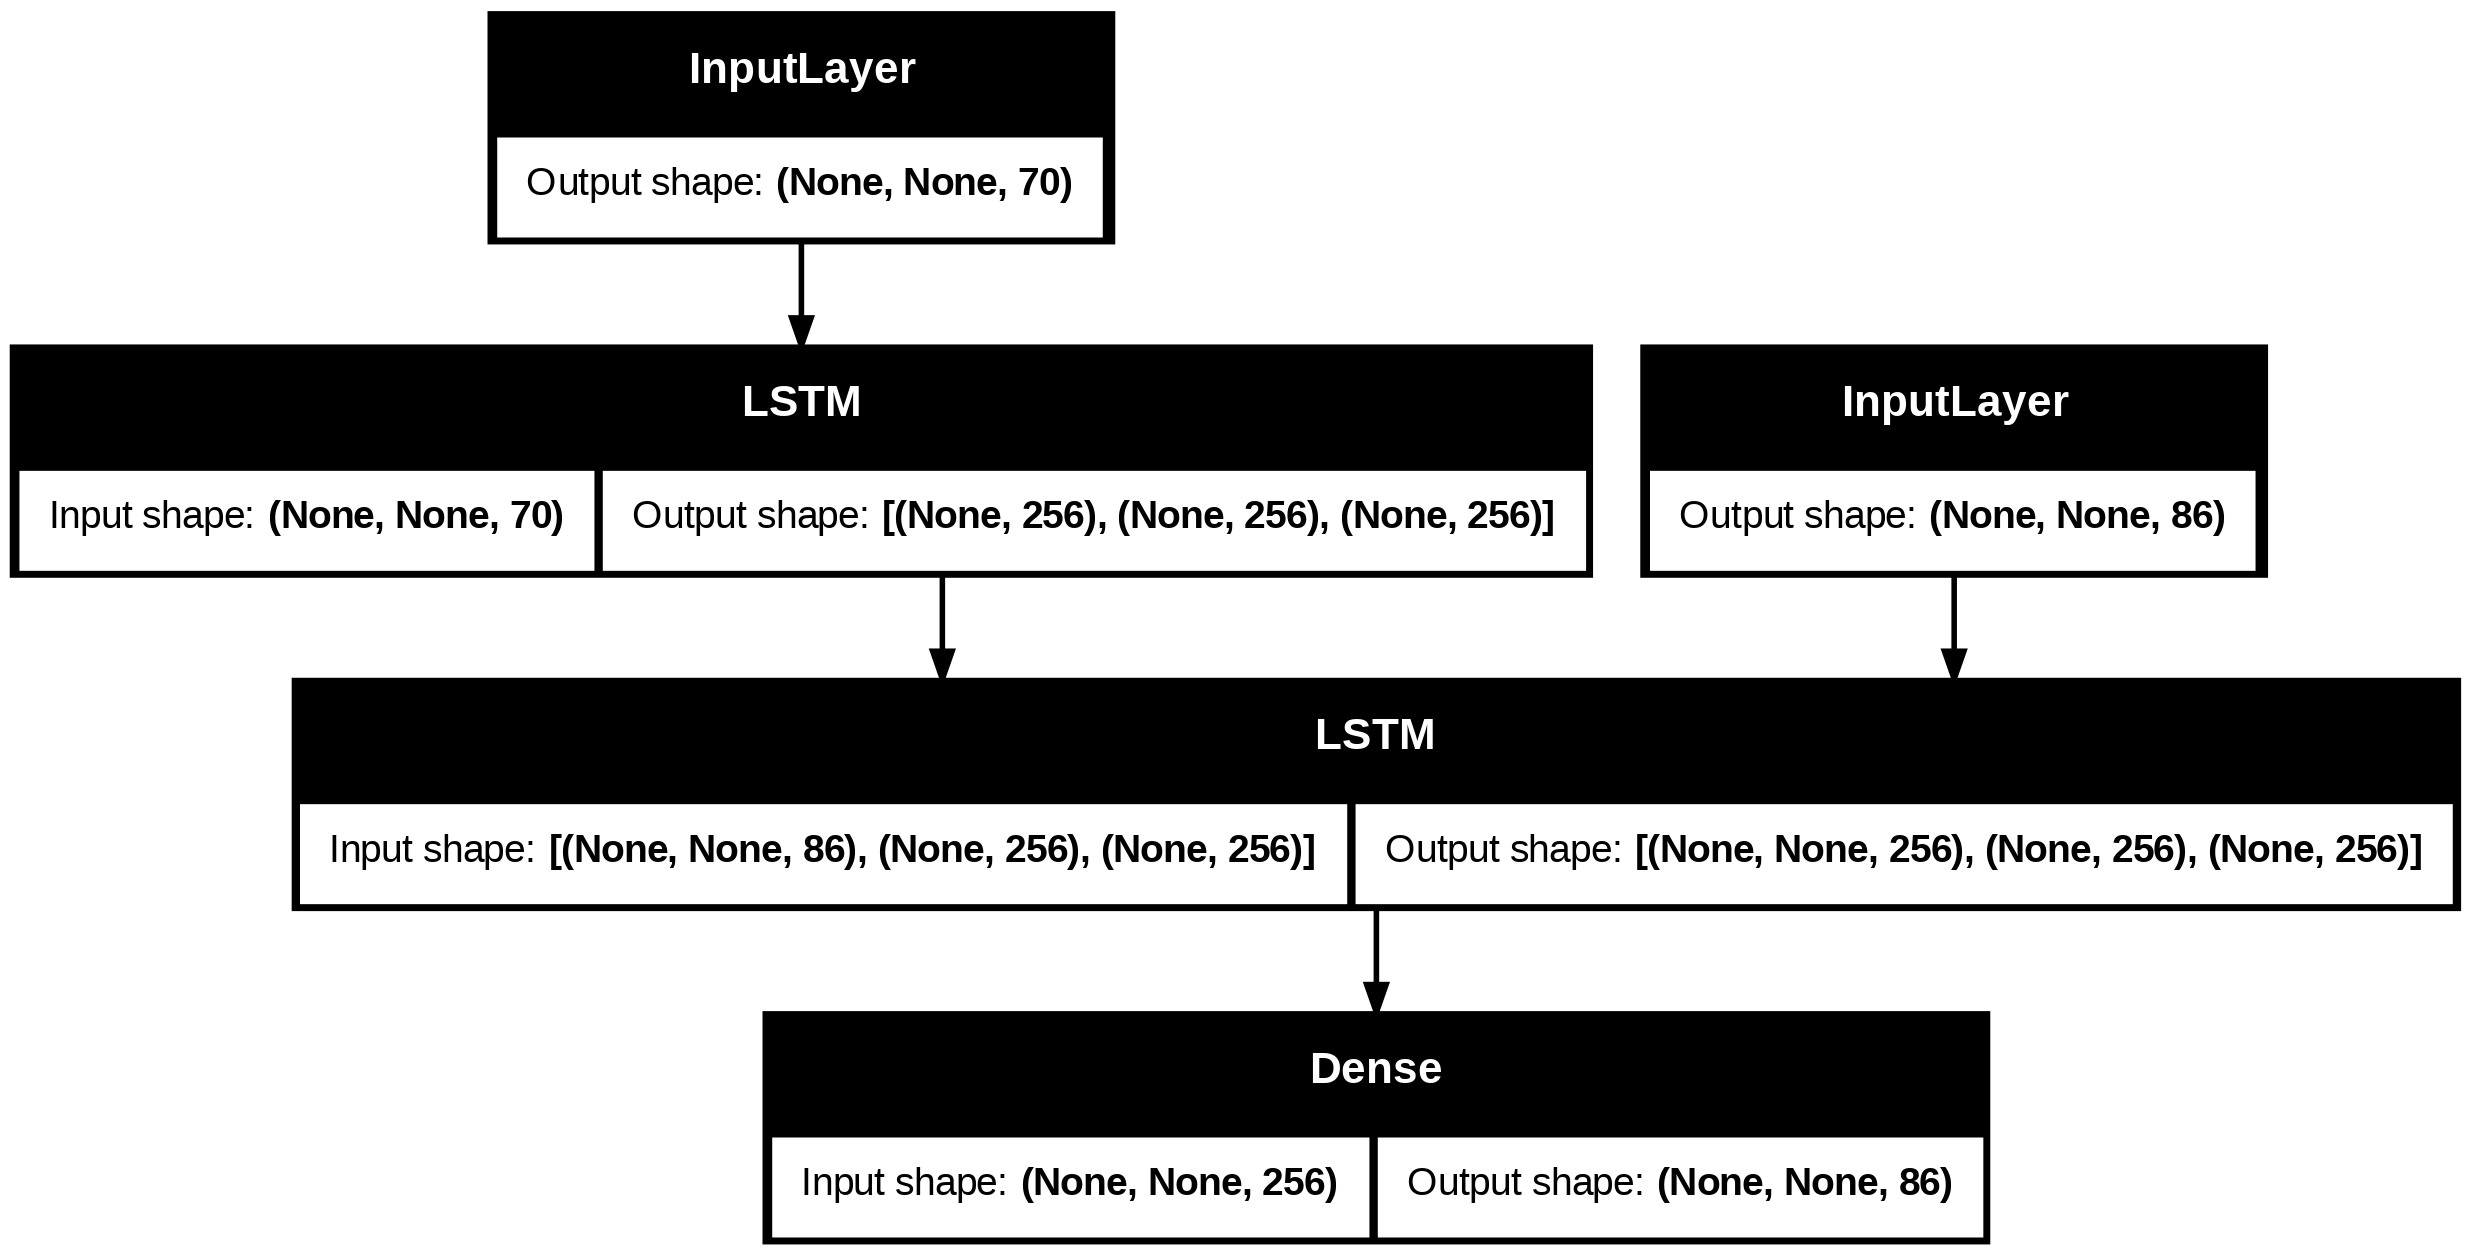

In [16]:
plot_model(model,show_shapes=True)

In [19]:
%%time
# Run training
from keras.optimizers import *
model.compile(optimizer=Adam(learning_rate=0.01, beta_1=0.9, beta_2=0.999), loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit([encoder_input_data, decoder_input_data], decoder_target_data,
          batch_size=BATCH_SIZE,
          epochs=NB_EPOCH,
          validation_split=0.2)

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 52s 386ms/step - accuracy: 0.0754 - loss: 1.0652 - val_accuracy: 0.0967 - val_loss: 1.1695
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 78s 360ms/step - accuracy: 0.0984 - loss: 0.9540 - val_accuracy: 0.1054 - val_loss: 1.1064
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 358ms/step - accuracy: 0.1105 - loss: 0.8922 - val_accuracy: 0.1259 - val_loss: 1.0257
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 363ms/step - accuracy: 0.1202 - loss: 0.8536 - val_accuracy: 0.1129 - val_loss: 1.1083
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 362ms/step - accuracy: 0.1226 - loss: 0.8445 - val_accuracy: 0.1404 - val_loss: 0.9598
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 50s 401ms/step - accuracy: 0.1375 - loss: 0.7856 - val_accuracy: 0.1628 - val_loss: 0.8969
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 47s 379ms/step - accuracy: 0.1581 - loss: 0.7087 - val_accuracy: 0.1739 - val_loss: 0.8526
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 80s 361ms/step - accuracy: 0.1711 -

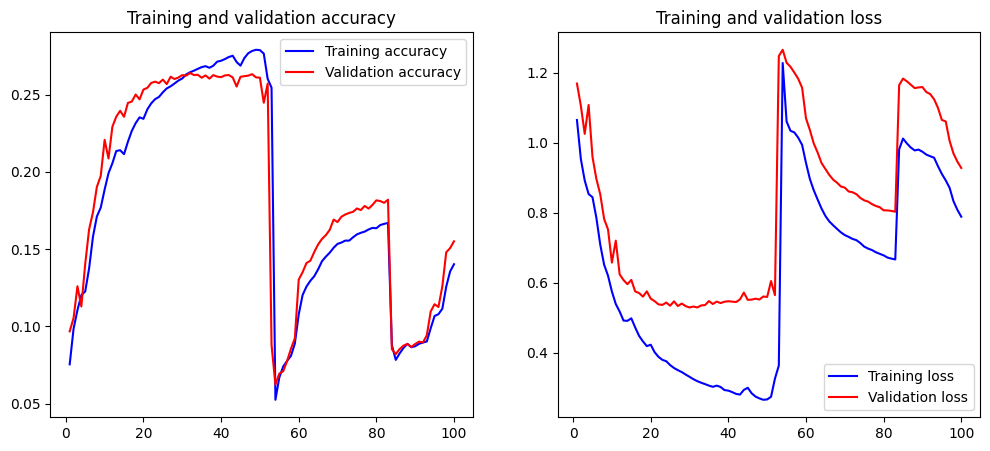

In [20]:

import matplotlib.pyplot as plt
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training accuracy')
    plt.plot(x, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
plot_history(history)

In [21]:
# Definindo modelo de previsão
encoder_model = Model(encoder_inputs, encoder_states)
decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))
decoder_states_inputs = [decoder_state_input_h, decoder_state_input_c]
decoder_outputs, state_h, state_c = decoder_lstm(decoder_inputs, initial_state=decoder_states_inputs)
decoder_states = [state_h, state_c]
decoder_outputs = decoder_dense(decoder_outputs)
decoder_model = Model(
    [decoder_inputs] + decoder_states_inputs,
    [decoder_outputs] + decoder_states)

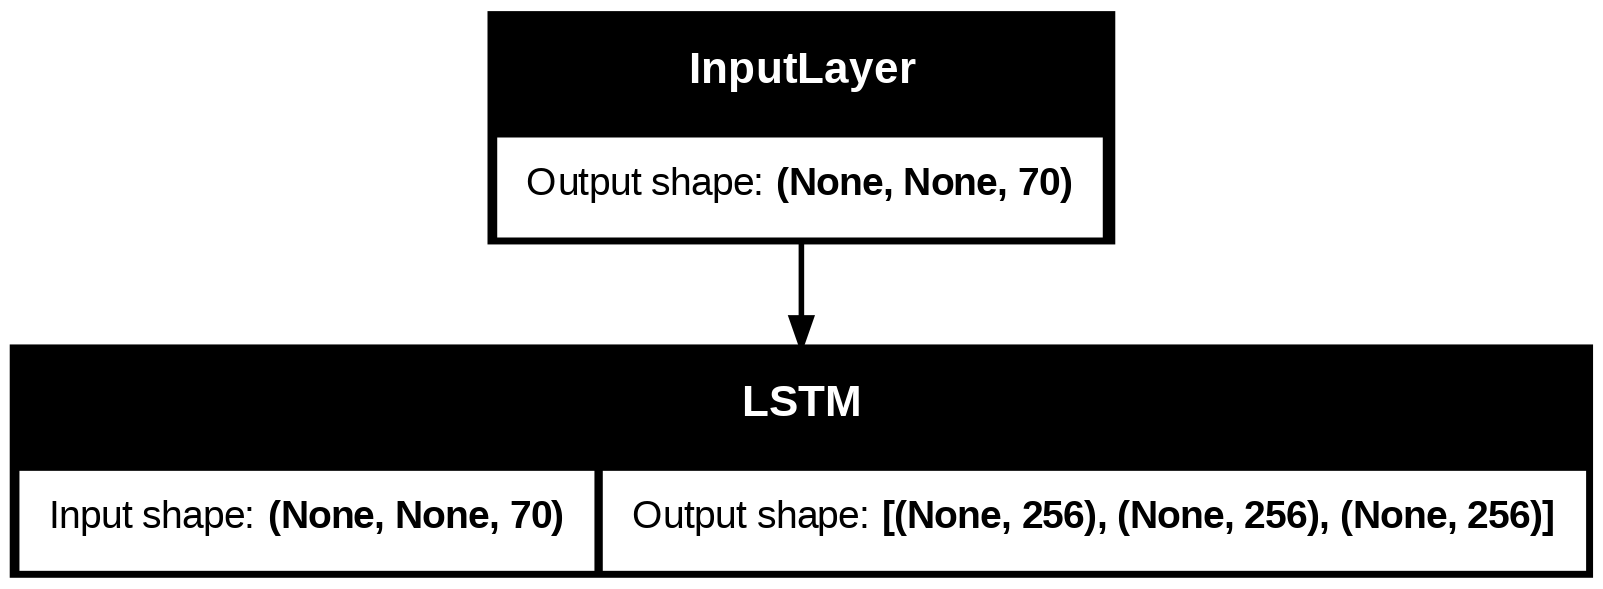

In [22]:
# Plotando o encoder de inferência
plot_model(encoder_model, show_shapes=True)

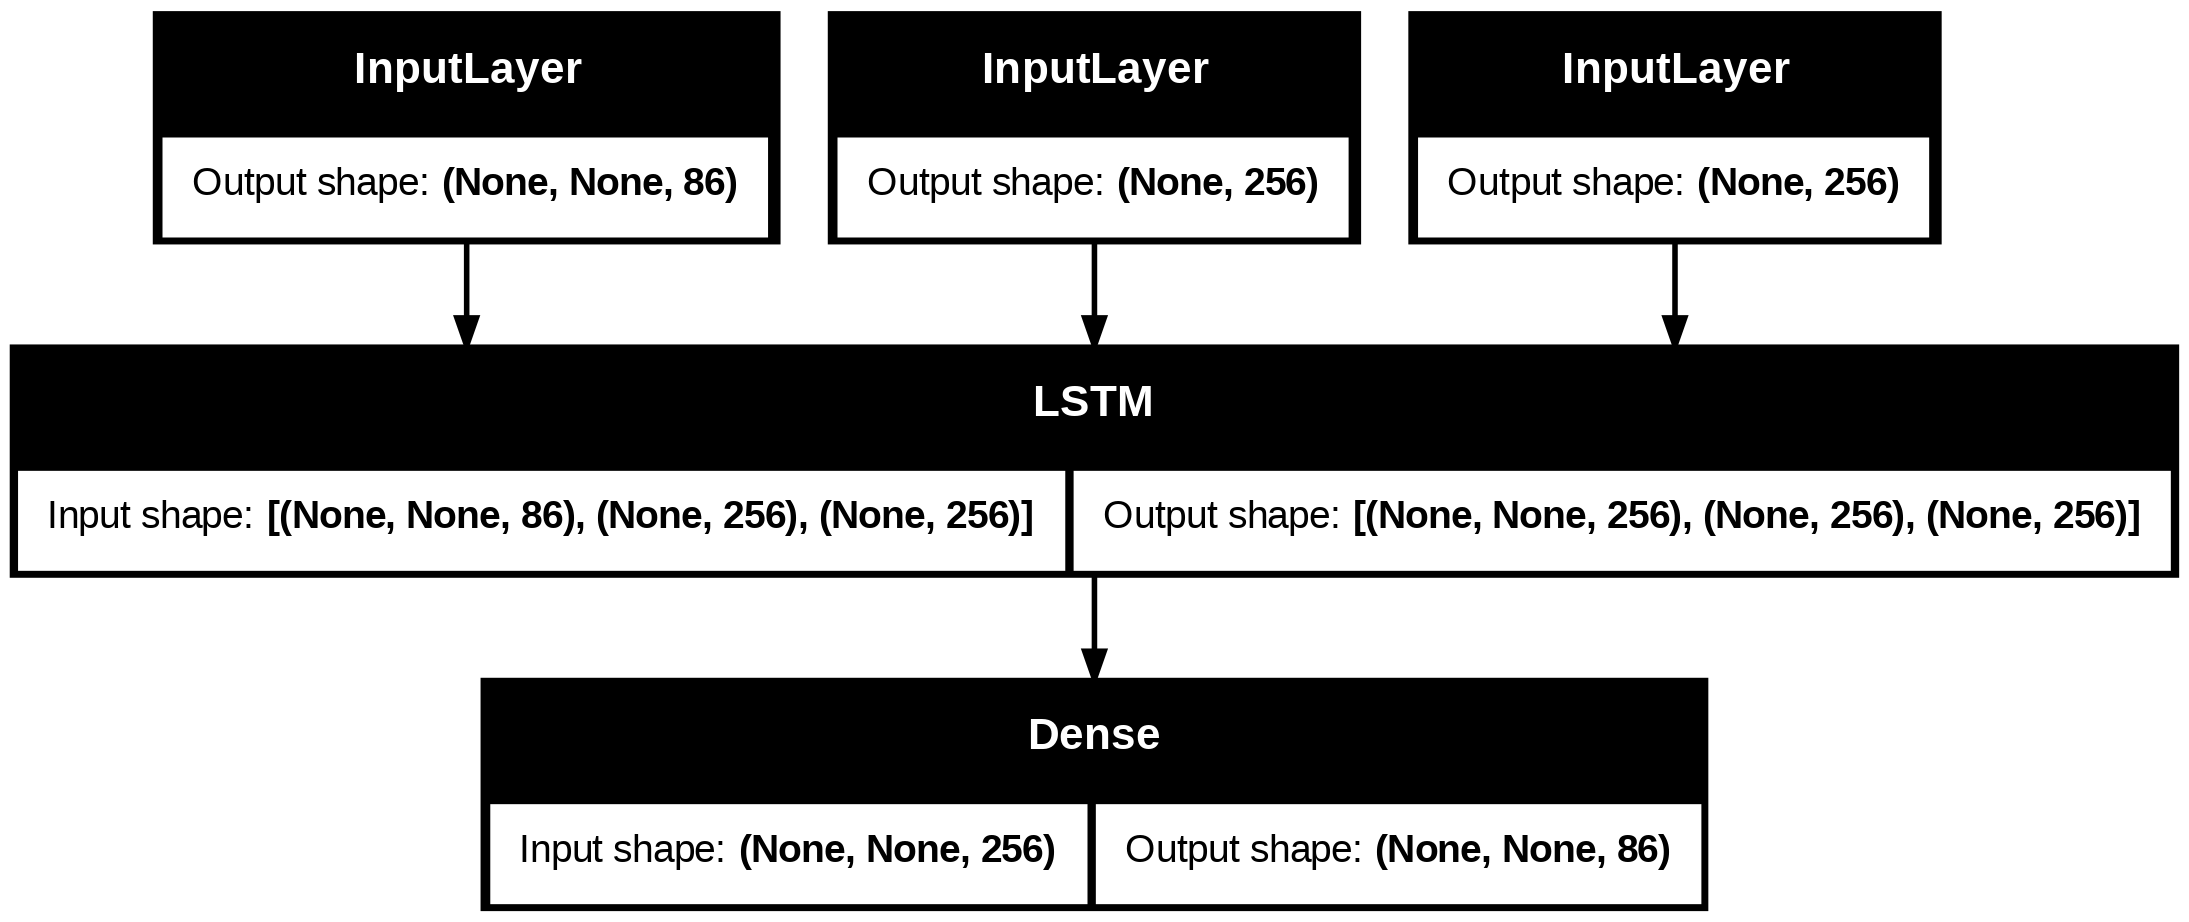

In [23]:
# Plotando o decoder de inferência
plot_model(decoder_model, show_shapes=True)

In [24]:
# Criação da função final para a tradução
reverse_input_char_index = dict((i, char) for char, i in input_token_index.items())
reverse_target_char_index = dict((i, char) for char, i in target_token_index.items())

def translate_eng_por(input_seq):
    # Cria primeiro o vetor oculto de estados com o encoder (encoder_model)
    states_value = encoder_model.predict(input_seq)

    # Cria uma sequência target vazia
    target_seq = np.zeros((1, 1, num_decoder_tokens))
    # Poopula a sequência com o caractere '\t'
    target_seq[0, 0, target_token_index['\t']] = 1.

    # Loop para formar a saída utilizando o decoder (decoder_model), até encontrar '\n' ou o limite de caracteres
    stop_condition = False
    decoded_sentence = ''
    while not stop_condition:
        output_tokens, h, c = decoder_model.predict([target_seq] + states_value)
        # Para cada token
        sampled_token_index = np.argmax(output_tokens[0, -1, :])
        sampled_char = reverse_target_char_index[sampled_token_index]
        decoded_sentence += sampled_char
        # Condição de parada, caso encontre o tamanho máximo ou '\n'
        if (sampled_char == '\n' or
           len(decoded_sentence) > max_decoder_seq_length):
            stop_condition = True
        # Atualiza a sequência de saída (target_seq)
        target_seq = np.zeros((1, 1, num_decoder_tokens))
        target_seq[0, 0, sampled_token_index] = 1.
        # Atualiza os estados para a próxima previsão
        states_value = [h, c]
    return decoded_sentence

In [ ]:
# Testando o modelo para os primeiros 100 exemplos
for seq_index in range(100):
    input_seq = encoder_input_data[seq_index: seq_index + 1]
    decoded_sentence = translate_eng_por(input_seq)
    print('-')
    print('Input:', input_texts[seq_index])
    print('Output:', decoded_sentence)

Streaming output truncated to the last 5000 lines.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/st